# Binary Classification - Merged Dataset

## Goal
Train a **binary TFLite model** (Cancer vs Non-cancer) using a **merged dataset** from:
- `oral_cavity_binary_dataset` (cancer / non-cancer folders)
- `oral_cavity_5class_dataset` mapped to binary:
  - Cancer = OCA + OPMD
  - Non-cancer = Benign + Healthy
  - **Unknown is excluded entirely**

## Baseline Reference
- Best TFLite 5-class model: 69.66% accuracy (evaluated on **5-class test set only**)
- This notebook aims to match or beat that with a simpler binary model on merged data.
- **Note:** 69.66% is not directly comparable: that model was tested on the same 5-class dataset; here we evaluate on a **merged** test set (binary + 5-class). See `BINARY_MERGED_ANALYSIS.md` for real-world usage analysis.

## Training Setup (Two-Phase Transfer Learning)
- **Phase 1**: Frozen MobileNetV3Large backbone, train head only (Adam lr=1e-3, 15 epochs)
- **Phase 2**: Fine-tune top backbone layers (Adam lr=1e-5, early stopping)
- Class weights for slight imbalance; augmentation: flip, brightness, contrast, rotation, zoom
- Batch size 32, early stopping patience=5

## Where Best Models Are Saved
Each run creates a timestamped folder under `results/binary_merged/run_YYYYMMDD_HHMMSS/`:
- **Keras (best by val_loss)**: `.../models/binary_model.keras`
- **TFLite (dynamic range)**: `.../tflite/binary_merged_dynamic.tflite`
- **TFLite (float16)**: `.../tflite/binary_merged_float16.tflite`
- Plots and evaluation JSON are in the same run folder.

In [1]:
# Cell 1: Config and Setup

import os
import json
import random
import shutil
from pathlib import Path
from datetime import datetime
from collections import Counter

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
from tqdm import tqdm

# M1 MacBook Pro optimizations
os.environ['TF_XLA_FLAGS'] = '--tf_xla_enable_xla_devices=false'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
tf.config.optimizer.set_jit(False)

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

# Check GPU
gpus = tf.config.list_physical_devices('GPU')
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(gpus) > 0}")
if gpus:
    print(f"GPU devices: {gpus}")

# Configuration - matches best TFLite model
CONFIG = {
    # Source data paths
    'data_dir_binary': os.path.expanduser('~/dev/oral_cavity_binary_dataset'),
    'data_dir_5class': os.path.expanduser('~/dev/oral_cavity_5class_dataset'),
    
    # Model config - EXACT match to best TFLite model
    'image_size': (224, 224),
    'batch_size': 32,
    'learning_rate': 1e-4,
    'epochs': 30,
    'early_stopping_patience': 5,
    'dropout_rate': 0.2,
    
    # Train/val/test split ratios (for binary dataset which has no splits)
    'val_split': 0.15,
    'test_split': 0.15,
    
    # Agent-tunable (overridden by agent_run_config.json when present)
    'use_class_weights': True,
    'augmentation': 'full',  # 'none' | 'light' | 'full'
    'phase1_epochs': 15,
}

# Agent mode: load overrides from agent_run_config.json (written by train_binary_merged_agent.py)
AGENT_RUN = False
_agent_config_path = Path('agent_run_config.json')
if _agent_config_path.exists():
    with open(_agent_config_path) as f:
        _overrides = json.load(f)
    CONFIG.update(_overrides)
    AGENT_RUN = True
    print(f"[Agent mode] Loaded overrides: {list(_overrides.keys())}")

# Output directory
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
OUTPUT_DIR = Path(f'results/binary_merged/run_{timestamp}')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'models').mkdir(exist_ok=True)
(OUTPUT_DIR / 'tflite').mkdir(exist_ok=True)
(OUTPUT_DIR / 'plots').mkdir(exist_ok=True)

# Save config
with open(OUTPUT_DIR / 'config.json', 'w') as f:
    json.dump(CONFIG, f, indent=2)

print(f"\nConfiguration:")
print(f"  Output directory: {OUTPUT_DIR}")
print(f"  Image size: {CONFIG['image_size']}")
print(f"  Batch size: {CONFIG['batch_size']}")
print(f"  Learning rate: {CONFIG['learning_rate']}")

TensorFlow version: 2.15.0
GPU available: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Configuration:
  Output directory: results/binary_merged/run_20260129_152953
  Image size: (224, 224)
  Batch size: 32
  Learning rate: 0.0001


In [2]:
# Cell 2: Load and Merge Datasets (using frozen test sets T5, TB, TM)
# Training pool = 5-class train+val only (T5 excluded) + binary train+val only (TB excluded).
# Evaluation uses frozen T5, TB, TM in Cell 8.

import sys
sys.path.insert(0, str(Path('.').resolve()))
from frozen_test_sets import (
    build_and_save_frozen_sets,
    load_frozen_sets,
    get_binary_train_val_for_training,
)

def collect_images_from_folder(folder_path, extensions=['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG']):
    """Collect all image paths from a folder."""
    folder = Path(folder_path)
    images = []
    if folder.exists():
        for ext in extensions:
            images.extend([str(p) for p in folder.glob(ext)])
    return images

FROZEN_DIR = Path('frozen_test_sets')
# Build frozen sets if not present (creates T5, TB, TM and binary_train_val manifest)
build_and_save_frozen_sets(
    data_dir_5class=CONFIG['data_dir_5class'],
    data_dir_binary=CONFIG['data_dir_binary'],
    out_dir=FROZEN_DIR,
)

print("Loading and merging datasets (training pool only; T5 and TB excluded)...")
print("=" * 60)

# --- SOURCE 1: Binary Dataset (train+val only; TB is frozen test) ---
print("\n[1] Binary Dataset (train+val only)")
binary_train_val_paths, binary_train_val_labels = get_binary_train_val_for_training(
    CONFIG['data_dir_binary'], FROZEN_DIR
)
binary_cancer = [p for p, lb in zip(binary_train_val_paths, binary_train_val_labels) if lb == 1]
binary_non_cancer = [p for p, lb in zip(binary_train_val_paths, binary_train_val_labels) if lb == 0]
print(f"    cancer (train+val): {len(binary_cancer)} images")
print(f"    non-cancer (train+val): {len(binary_non_cancer)} images")
print(f"    Total (TB excluded): {len(binary_cancer) + len(binary_non_cancer)} images")

# --- SOURCE 2: 5-Class Dataset train+val only (T5 = test excluded) ---
print("\n[2] 5-Class Dataset (train+val only; T5 excluded)")
five_class_dir = Path(CONFIG['data_dir_5class'])
five_class_cancer = []
five_class_non_cancer = []

for split in ['train', 'val']:
    split_dir = five_class_dir / split
    if split_dir.exists():
        for cancer_class in ['OCA', 'OPMD']:
            imgs = collect_images_from_folder(split_dir / cancer_class)
            five_class_cancer.extend(imgs)
            print(f"    {split}/{cancer_class}: {len(imgs)} images")
        for non_cancer_class in ['Benign', 'Healthy']:
            imgs = collect_images_from_folder(split_dir / non_cancer_class)
            five_class_non_cancer.extend(imgs)
            print(f"    {split}/{non_cancer_class}: {len(imgs)} images")

print(f"\n    5-class Cancer (OCA+OPMD, train+val): {len(five_class_cancer)} images")
print(f"    5-class Non-cancer (Benign+Healthy, train+val): {len(five_class_non_cancer)} images")

# --- MERGE (training pool only) ---
print("\n[3] Merged training pool")
print("-" * 40)

all_cancer = binary_cancer + five_class_cancer
all_non_cancer = binary_non_cancer + five_class_non_cancer
all_cancer = list(set(all_cancer))
all_non_cancer = list(set(all_non_cancer))

print(f"    CANCER (merged): {len(all_cancer)} images")
print(f"        From binary (train+val): {len(binary_cancer)}")
print(f"        From 5-class (train+val): {len(five_class_cancer)}")
print(f"\n    NON-CANCER (merged): {len(all_non_cancer)} images")
print(f"        From binary (train+val): {len(binary_non_cancer)}")
print(f"        From 5-class (train+val): {len(five_class_non_cancer)}")

total_images = len(all_cancer) + len(all_non_cancer)
print(f"\n    TOTAL TRAINING POOL: {total_images} images")
print(f"    Class balance: Cancer {len(all_cancer)/total_images*100:.1f}% / Non-cancer {len(all_non_cancer)/total_images*100:.1f}%")
print(f"\n    Test sets (frozen): T5, TB, TM -> evaluated in Cell 8")

Loading and merging datasets...

[1] Binary Dataset
    cancer/: 884 images
    non-cancer/: 750 images
    Total: 1634 images

[2] 5-Class Dataset (mapped to binary, excluding Unknown)
    train/OCA: 216 images
    train/OPMD: 975 images
    train/Benign: 656 images
    train/Healthy: 510 images
    val/OCA: 35 images
    val/OPMD: 209 images
    val/Benign: 128 images
    val/Healthy: 109 images
    test/OCA: 36 images
    test/OPMD: 209 images
    test/Benign: 129 images
    test/Healthy: 110 images

    5-class Cancer (OCA+OPMD): 1680 images
    5-class Non-cancer (Benign+Healthy): 1642 images

[3] Merged Dataset
----------------------------------------
    CANCER (merged): 2564 images
        From binary dataset: 884
        From 5-class (OCA+OPMD): 1680
        After dedup: 2564

    NON-CANCER (merged): 2392 images
        From binary dataset: 750
        From 5-class (Benign+Healthy): 1642
        After dedup: 2392

    TOTAL MERGED: 4956 images
    Class balance: Cancer 51.7% 

In [3]:
# Cell 3: Create Train/Val Split (no test here; test = frozen T5, TB, TM)

print("Creating train/val split (test sets T5, TB, TM are frozen)...")
print("=" * 60)

all_paths = all_cancer + all_non_cancer
all_labels = [1] * len(all_cancer) + [0] * len(all_non_cancer)  # 1=cancer, 0=non-cancer

# Single split: train vs val (no test; test is T5, TB, TM)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_paths, all_labels,
    test_size=CONFIG['val_split'],
    random_state=SEED,
    stratify=all_labels
)

print(f"\nSplit Summary:")
print(f"  Train: {len(train_paths)} images")
print(f"      Cancer: {sum(train_labels)} ({sum(train_labels)/len(train_labels)*100:.1f}%)")
print(f"      Non-cancer: {len(train_labels) - sum(train_labels)} ({(len(train_labels) - sum(train_labels))/len(train_labels)*100:.1f}%)")

print(f"\n  Validation: {len(val_paths)} images")
print(f"      Cancer: {sum(val_labels)} ({sum(val_labels)/len(val_labels)*100:.1f}%)")
print(f"      Non-cancer: {len(val_labels) - sum(val_labels)} ({(len(val_labels) - sum(val_labels))/len(val_labels)*100:.1f}%)")

print(f"\n  Test: frozen T5, TB, TM (evaluated in Cell 8)")

split_info = {
    'train_count': len(train_paths),
    'val_count': len(val_paths),
    'train_cancer': sum(train_labels),
    'val_cancer': sum(val_labels),
}
with open(OUTPUT_DIR / 'split_info.json', 'w') as f:
    json.dump(split_info, f, indent=2)

Creating train/val/test splits...

Split Summary:
  Train: 3468 images
      Cancer: 1794 (51.7%)
      Non-cancer: 1674 (48.3%)

  Validation: 744 images
      Cancer: 385 (51.7%)
      Non-cancer: 359 (48.3%)

  Test: 744 images
      Cancer: 385 (51.7%)
      Non-cancer: 359 (48.3%)


In [4]:
# Cell 4: Create tf.data.Dataset Pipelines

print("Creating data pipelines...")
print("=" * 60)

AUTOTUNE = tf.data.AUTOTUNE

# First, validate all images and remove corrupted ones
print("\nValidating images (removing corrupted files)...")

def is_valid_image(path):
    """Check if a file is a valid image."""
    try:
        img_data = tf.io.read_file(path)
        # decode_image handles JPEG, PNG, GIF, BMP
        img = tf.image.decode_image(img_data, channels=3)
        return True
    except:
        return False

def validate_paths(paths, labels):
    """Remove paths to corrupted/invalid images."""
    valid_paths = []
    valid_labels = []
    invalid_count = 0
    
    for path, label in tqdm(zip(paths, labels), total=len(paths), desc="Validating"):
        if is_valid_image(path):
            valid_paths.append(path)
            valid_labels.append(label)
        else:
            invalid_count += 1
            print(f"  Invalid image: {path}")
    
    if invalid_count > 0:
        print(f"\n  Removed {invalid_count} invalid images")
    else:
        print(f"\n  All {len(paths)} images are valid")
    
    return valid_paths, valid_labels

# Validate all splits
print("\nValidating train set...")
train_paths, train_labels = validate_paths(train_paths, train_labels)
print("\nValidating val set...")
val_paths, val_labels = validate_paths(val_paths, val_labels)

print(f"\nAfter validation:")
print(f"  Train: {len(train_paths)} images")
print(f"  Val: {len(val_paths)} images")

def load_and_preprocess(path, label):
    """Load and preprocess a single image."""
    img = tf.io.read_file(path)
    # Use decode_image instead of decode_jpeg to handle multiple formats
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])  # Required after decode_image
    img = tf.image.resize(img, CONFIG['image_size'])
    img = tf.cast(img, tf.float32) / 255.0
    return img, tf.cast(label, tf.float32)

def augment(image, label):
    """Apply data augmentation. Level from CONFIG['augmentation']: none | light | full."""
    aug = CONFIG.get('augmentation', 'full')
    # Random horizontal flip (always)
    image = tf.image.random_flip_left_right(image)
    # Random rotation (0, 90, 180, 270) only for 'full'
    if aug == 'full':
        k = tf.random.uniform([], 0, 4, dtype=tf.int32)
        image = tf.image.rot90(image, k=k)
    # Random brightness and contrast
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    # Zoom (light and full)
    if aug in ('light', 'full'):
        h, w = tf.shape(image)[0], tf.shape(image)[1]
        crop_factor = tf.random.uniform([], 0.85, 1.0)
        image = tf.image.central_crop(image, crop_factor)
        image = tf.image.resize(image, [h, w])
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, label

def create_dataset(paths, labels, batch_size, shuffle=True, augment_data=False):
    """Create a tf.data.Dataset from paths and labels."""
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED)
    
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    
    if augment_data:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    
    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    
    return ds

# Create datasets (test = frozen T5, TB, TM evaluated in Cell 8)
train_ds = create_dataset(train_paths, train_labels, CONFIG['batch_size'], shuffle=True, augment_data=True)
val_ds = create_dataset(val_paths, val_labels, CONFIG['batch_size'], shuffle=False, augment_data=False)

print(f"Datasets created:")
print(f"  Train: {len(train_paths)} samples, {len(train_paths) // CONFIG['batch_size']} batches")
print(f"  Val: {len(val_paths)} samples, {len(val_paths) // CONFIG['batch_size']} batches")

Creating data pipelines...

Validating images (removing corrupted files)...

Validating train set...


Validating:   1%|█▊                                                                                                                                         | 44/3468 [00:02<01:59, 28.60it/s]

  Invalid image: /Users/alokdwivedi/dev/oral_cavity_binary_dataset/cancer/428.jpeg


Validating:   4%|█████▊                                                                                                                                    | 145/3468 [00:06<02:08, 25.95it/s]

  Invalid image: /Users/alokdwivedi/dev/oral_cavity_binary_dataset/non-cancer/073.jpeg


...

  Invalid image: /Users/alokdwivedi/dev/oral_cavity_binary_dataset/cancer/108.jpeg


Validating:  81%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████                           | 600/744 [00:25<00:06, 23.90it/s]

  Invalid image: /Users/alokdwivedi/dev/oral_cavity_binary_dataset/cancer/387.jpeg


Validating: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 744/744 [00:31<00:00, 23.75it/s]



  Removed 7 invalid images

After validation:
  Train: 3440 images
  Val: 739 images
  Test: 737 images
Datasets created:
  Train: 3440 samples, 107 batches
  Val: 739 samples, 23 batches
  Test: 737 samples, 23 batches


In [5]:
# Cell 5: Build Model (MobileNetV3Large - Two-Phase Transfer Learning)
# FIX: Proper transfer learning with frozen backbone first, then fine-tuning

print("Building Binary Classification Model...")
print("=" * 60)

# Load pre-trained MobileNetV3Large as a separate variable (for fine-tuning later)
base_model = MobileNetV3Large(
    weights='imagenet',
    include_top=False,
    input_shape=(*CONFIG['image_size'], 3),
    alpha=1.0,
    minimalistic=False
)

# CRITICAL FIX: Freeze the base model for Phase 1
# Without this, random head gradients destroy pretrained features
base_model.trainable = False

# Build classification head
inputs = layers.Input(shape=(*CONFIG['image_size'], 3))
x = base_model(inputs, training=False)  # Always use inference mode for frozen backbone
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(1280, activation='relu')(x)
x = layers.Dropout(CONFIG['dropout_rate'])(x)
outputs = layers.Dense(1, activation='sigmoid')(x)

model = Model(inputs, outputs)

# Compile for Phase 1 (frozen backbone) - use HIGHER LR for head training
# 1e-3 is standard for training new layers on frozen backbone
model.compile(
    optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Count trainable vs non-trainable params
trainable_count = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
non_trainable_count = sum([tf.keras.backend.count_params(w) for w in model.non_trainable_weights])

print(f"\nModel Summary (Phase 1 - Frozen Backbone):")
print(f"  Architecture: MobileNetV3Large + Dense(1280) + Dropout({CONFIG['dropout_rate']}) + Dense(1, sigmoid)")
print(f"  Total Parameters: {model.count_params():,}")
print(f"  Trainable Parameters: {trainable_count:,} (head only)")
print(f"  Non-trainable Parameters: {non_trainable_count:,} (frozen backbone)")
print(f"  Optimizer: Adam (lr=1e-3)")
print(f"  Loss: binary_crossentropy")

Building Binary Classification Model...

Model Summary (Phase 1 - Frozen Backbone):
  Architecture: MobileNetV3Large + Dense(1280) + Dropout(0.2) + Dense(1, sigmoid)
  Total Parameters: 4,227,713
  Trainable Parameters: 1,231,361 (head only)
  Non-trainable Parameters: 2,996,352 (frozen backbone)
  Optimizer: Adam (lr=1e-3)
  Loss: binary_crossentropy


In [6]:
# Cell 6: Train Model (Two-Phase Transfer Learning)

# Class weights (optional, from CONFIG for agent runs)
CLASS_WEIGHT = None
if CONFIG.get('use_class_weights', True):
    classes = np.unique(train_labels)
    weights = compute_class_weight('balanced', classes=classes, y=train_labels)
    CLASS_WEIGHT = dict(zip(classes, weights))
    print("Class weights (0=non-cancer, 1=cancer):", CLASS_WEIGHT)
else:
    print("Class weights: disabled")

print("=" * 60)
print("PHASE 1: Training Classification Head (Frozen Backbone)")
print("=" * 60)

# Model path
model_path = str(OUTPUT_DIR / 'models' / 'binary_model.keras')

# Phase 1 Callbacks
phase1_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        model_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

# Phase 1: Train head with frozen backbone (epochs from CONFIG, optional class_weight)
phase1_epochs = CONFIG.get('phase1_epochs', 15)
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=phase1_epochs,
    class_weight=CLASS_WEIGHT,
    callbacks=phase1_callbacks,
    verbose=1
)

print(f"\nPhase 1 complete!")
print(f"  Best val_loss: {min(history1.history['val_loss']):.4f}")
print(f"  Best val_accuracy: {max(history1.history['val_accuracy']):.4f}")

# ============================================================
# PHASE 2: Fine-tune top backbone layers
# ============================================================
print("\n" + "=" * 60)
print("PHASE 2: Fine-Tuning Top Backbone Layers")
print("=" * 60)

# Unfreeze top layers of the backbone
base_model.trainable = True

# Freeze bottom layers, keep top ~30% trainable
# MobileNetV3Large has ~150 layers, unfreeze top ~50
fine_tune_from = 100
for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

# Recompile with LOWER learning rate for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=1e-5),  # Very low LR for fine-tuning
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Count updated trainable params
trainable_count = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
non_trainable_count = sum([tf.keras.backend.count_params(w) for w in model.non_trainable_weights])
print(f"\nFine-tuning from layer {fine_tune_from}")
print(f"  Trainable Parameters: {trainable_count:,}")
print(f"  Non-trainable Parameters: {non_trainable_count:,}")
print(f"  Optimizer: Adam (lr=1e-5)")

# Phase 2 Callbacks
phase2_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=CONFIG['early_stopping_patience'],
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        model_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

# Phase 2: Fine-tune with more epochs
total_epochs = CONFIG['epochs']
initial_epochs = len(history1.history['loss'])

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=initial_epochs,
    class_weight=CLASS_WEIGHT,
    callbacks=phase2_callbacks,
    verbose=1
)

# Combine histories
history = {
    'loss': history1.history['loss'] + history2.history['loss'],
    'val_loss': history1.history['val_loss'] + history2.history['val_loss'],
    'accuracy': history1.history['accuracy'] + history2.history['accuracy'],
    'val_accuracy': history1.history['val_accuracy'] + history2.history['val_accuracy'],
}

# Save combined training history
with open(OUTPUT_DIR / 'training_history.json', 'w') as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history.items()}, f, indent=2)

print(f"\n" + "=" * 60)
print("Training Complete!")
print("=" * 60)
print(f"  Phase 1 epochs: {initial_epochs}")
print(f"  Phase 2 epochs: {len(history2.history['loss'])}")
print(f"  Best val_loss: {min(history['val_loss']):.4f}")
print(f"  Best val_accuracy: {max(history['val_accuracy']):.4f}")
print(f"  Model saved to: {model_path}")

Class weights (0=non-cancer, 1=cancer): {0: 1.0324129651860745, 1: 0.9695603156708005}
PHASE 1: Training Classification Head (Frozen Backbone)
Epoch 1/15
108/108 [==============================] - ETA: 0s - loss: 0.7363 - accuracy: 0.4904
Epoch 1: val_loss improved from inf to 0.69123, saving model to results/binary_merged/run_20260129_152953/models/binary_model.keras
108/108 [==============================] - 35s 307ms/step - loss: 0.7363 - accuracy: 0.4904 - val_loss: 0.6912 - val_accuracy: 0.5115
Epoch 2/15
108/108 [==============================] - ETA: 0s - loss: 0.7014 - accuracy: 0.5180
Epoch 2: val_loss did not improve from 0.69123
108/108 [==============================] - 31s 288ms/step - loss: 0.7014 - accuracy: 0.5180 - val_loss: 0.6982 - val_accuracy: 0.4885
Epoch 3/15
108/108 [==============================] - ETA: 0s - loss: 0.7044 - accuracy: 0.5201
Epoch 3: val_loss did not improve from 0.69123
108/108 [==============================] - 31s 290ms/step - loss: 0.7044 - 

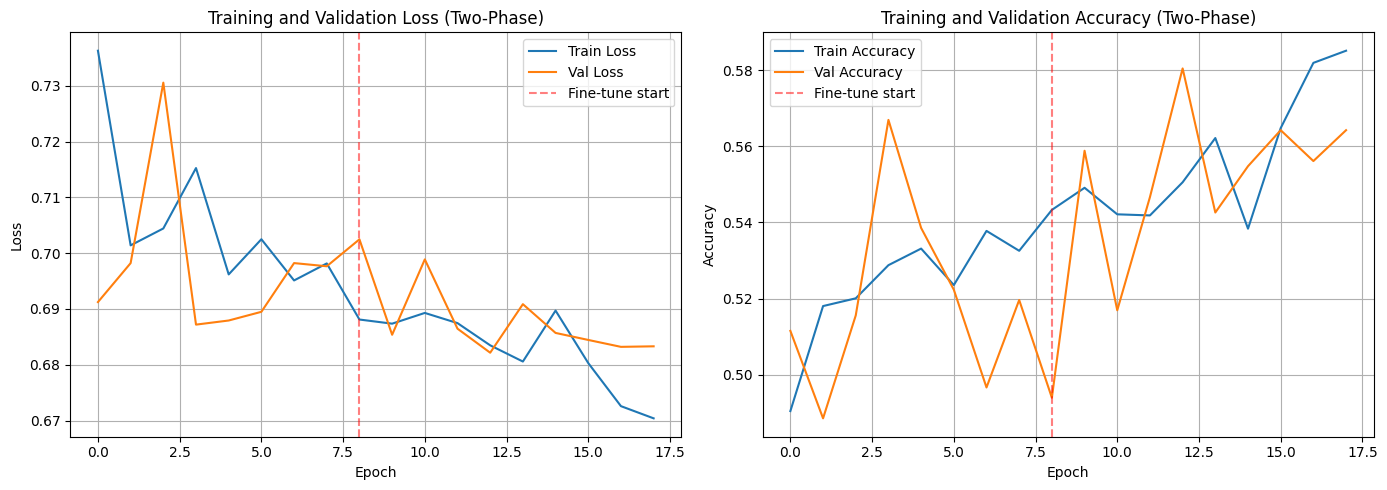

Training curves saved to: results/binary_merged/run_20260129_152953/plots/training_curves.png


In [7]:
# Cell 7: Plot Training History (Two-Phase)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Get phase boundary for visualization
phase1_epochs = len(history1.history['loss'])

# Loss plot
axes[0].plot(history['loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].axvline(x=phase1_epochs-1, color='red', linestyle='--', alpha=0.5, label='Fine-tune start')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss (Two-Phase)')
axes[0].legend()
axes[0].grid(True)

# Accuracy plot
axes[1].plot(history['accuracy'], label='Train Accuracy')
axes[1].plot(history['val_accuracy'], label='Val Accuracy')
axes[1].axvline(x=phase1_epochs-1, color='red', linestyle='--', alpha=0.5, label='Fine-tune start')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy (Two-Phase)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'plots' / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Training curves saved to: {OUTPUT_DIR / 'plots' / 'training_curves.png'}")

In [8]:
# Cell 8: Evaluate on Frozen Test Sets (T5, TB, TM) for comparable results

from frozen_test_sets import (
    get_t5_binary_paths_labels,
    get_tb_paths_labels,
    get_tm_paths_labels_and_sources,
)

print("Evaluating on frozen test sets T5, TB, TM...")
print("=" * 60)

best_model = keras.models.load_model(model_path)

def run_predictions(model, paths, labels, batch_size=32):
    """Run model on paths/labels; return (preds, probs, labels)."""
    ds = create_dataset(paths, labels, batch_size, shuffle=False, augment_data=False)
    all_preds, all_probs, all_true = [], [], []
    for images, lbls in tqdm(ds, desc="Predict", leave=False):
        probs = model.predict(images, verbose=0).flatten()
        preds = (probs >= 0.5).astype(int)
        all_probs.extend(probs.tolist())
        all_preds.extend(preds.tolist())
        all_true.extend(lbls.numpy().tolist())
    return np.array(all_preds), np.array(all_probs), np.array(all_true)

def metrics_dict(true, pred):
    """Accuracy, sensitivity (cancer), specificity (non-cancer)."""
    acc = float(np.mean(pred == true))
    cancer_mask = true == 1
    non_cancer_mask = true == 0
    sens = float(np.mean(pred[cancer_mask] == true[cancer_mask])) if cancer_mask.sum() else 0.0
    spec = float(np.mean(pred[non_cancer_mask] == true[non_cancer_mask])) if non_cancer_mask.sum() else 0.0
    return {"accuracy": acc, "sensitivity": sens, "specificity": spec, "n": len(true)}

# Load frozen sets
t5_paths, t5_labels = get_t5_binary_paths_labels(FROZEN_DIR)
tb_paths, tb_labels = get_tb_paths_labels(FROZEN_DIR)
tm_paths, tm_labels, tm_sources = get_tm_paths_labels_and_sources(FROZEN_DIR)

# Run on T5, TB, TM
t5_pred, t5_prob, t5_true = run_predictions(best_model, t5_paths, t5_labels, CONFIG["batch_size"])
tb_pred, tb_prob, tb_true = run_predictions(best_model, tb_paths, tb_labels, CONFIG["batch_size"])
tm_pred, tm_prob, tm_true = run_predictions(best_model, tm_paths, tm_labels, CONFIG["batch_size"])

m_t5 = metrics_dict(t5_true, t5_pred)
m_tb = metrics_dict(tb_true, tb_pred)
m_tm = metrics_dict(tm_true, tm_pred)

# Per-source metrics on TM (A = 5-class, B = binary)
tm_sources = np.array(tm_sources)
tm_a_mask = tm_sources == "A"
tm_b_mask = tm_sources == "B"
m_tm_A = metrics_dict(tm_true[tm_a_mask], tm_pred[tm_a_mask]) if tm_a_mask.sum() else {}
m_tm_B = metrics_dict(tm_true[tm_b_mask], tm_pred[tm_b_mask]) if tm_b_mask.sum() else {}

# Use TM accuracy as the main comparable metric (mixed test set)
accuracy = m_tm["accuracy"]
cancer_acc = m_tm["sensitivity"]
non_cancer_acc = m_tm["specificity"]
all_true = tm_true
all_preds = tm_pred

print(f"\n" + "=" * 60)
print(f"RESULTS: Binary Classification on Frozen Test Sets (T5, TB, TM)")
print(f"=" * 60)

print(f"\n--- T5 (5-class-only test) ---")
print(f"  n={m_t5['n']}  Accuracy={m_t5['accuracy']*100:.2f}%  Sensitivity={m_t5['sensitivity']*100:.2f}%  Specificity={m_t5['specificity']*100:.2f}%")

print(f"\n--- TB (binary-only test) ---")
print(f"  n={m_tb['n']}  Accuracy={m_tb['accuracy']*100:.2f}%  Sensitivity={m_tb['sensitivity']*100:.2f}%  Specificity={m_tb['specificity']*100:.2f}%")

print(f"\n--- TM (mixed merged test) ---")
print(f"  n={m_tm['n']}  Accuracy={m_tm['accuracy']*100:.2f}%  Sensitivity={m_tm['sensitivity']*100:.2f}%  Specificity={m_tm['specificity']*100:.2f}%")

print(f"\n--- TM per-source (transfer) ---")
print(f"  Source A (5-class): n={m_tm_A.get('n',0)}  Accuracy={m_tm_A.get('accuracy',0)*100:.2f}%  Sens={m_tm_A.get('sensitivity',0)*100:.2f}%  Spec={m_tm_A.get('specificity',0)*100:.2f}%")
print(f"  Source B (binary): n={m_tm_B.get('n',0)}  Accuracy={m_tm_B.get('accuracy',0)*100:.2f}%  Sens={m_tm_B.get('sensitivity',0)*100:.2f}%  Spec={m_tm_B.get('specificity',0)*100:.2f}%")

# Confusion matrix on TM
cm = confusion_matrix(tm_true, tm_pred)
print(f"\nConfusion Matrix (TM):")
print(f"                  Predicted")
print(f"                  Non-cancer  Cancer")
print(f"  Actual Non-cancer:  {cm[0,0]:>6}    {cm[0,1]:>6}")
print(f"  Actual Cancer:      {cm[1,0]:>6}    {cm[1,1]:>6}")

# Save results (comparable across all models)
results = {
    "T5": m_t5,
    "TB": m_tb,
    "TM": m_tm,
    "TM_source_A": m_tm_A,
    "TM_source_B": m_tm_B,
    "confusion_matrix_TM": cm.tolist(),
}
with open(OUTPUT_DIR / "evaluation_results.json", "w") as f:
    json.dump(results, f, indent=2)

print(f"\nResults saved to: {OUTPUT_DIR / 'evaluation_results.json'}")

# Agent mode: use TM accuracy as primary (comparable metric)
if AGENT_RUN:
    agent_result_path = Path("results/binary_merged/agent_result.json")
    agent_result_path.parent.mkdir(parents=True, exist_ok=True)
    agent_result = {
        "accuracy": accuracy,
        "sensitivity": float(cancer_acc),
        "specificity": float(non_cancer_acc),
        "T5": m_t5,
        "TB": m_tb,
        "TM": m_tm,
        "TM_source_A": m_tm_A,
        "TM_source_B": m_tm_B,
        "output_dir": str(OUTPUT_DIR),
        "config_used": {k: v for k, v in CONFIG.items() if k in ("use_class_weights", "augmentation", "phase1_epochs")},
    }
    with open(agent_result_path, "w") as f:
        json.dump(agent_result, f, indent=2)
    print(f"[Agent] Wrote {agent_result_path}")

Evaluating on Test Set...


Evaluating: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:05<00:00,  4.02it/s]


RESULTS: Binary Classification (Merged Dataset)

Overall Accuracy: 56.58%

Dataset Size: 737 test samples
  Cancer: 381.0 (51.7%)
  Non-cancer: 356.0 (48.3%)

Per-Class Accuracy:
  Cancer: 72.70% (Sensitivity/Recall)
  Non-cancer: 39.33% (Specificity)

Confusion Matrix:
                  Predicted
                  Non-cancer  Cancer
  Actual Non-cancer:     140       216
  Actual Cancer:         104       277

Classification Report:
              precision    recall  f1-score   support

  Non-cancer       0.57      0.39      0.47       356
      Cancer       0.56      0.73      0.63       381

    accuracy                           0.57       737
   macro avg       0.57      0.56      0.55       737
weighted avg       0.57      0.57      0.55       737


Confidence Distribution:
  Mean probability: 0.526
  Min probability: 0.238
  Max probability: 0.767

Results saved to: results/binary_merged/run_20260129_152953/evaluation_results.json


In [9]:
# Cell 9: Convert to TFLite

print("Converting to TFLite...")
print("=" * 60)

def convert_to_tflite(model, output_path, quantization='dynamic'):
    """Convert Keras model to TFLite."""
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    
    if quantization == 'dynamic':
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
    elif quantization == 'float16':
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
    
    tflite_model = converter.convert()
    
    with open(output_path, 'wb') as f:
        f.write(tflite_model)
    
    size_mb = len(tflite_model) / (1024 * 1024)
    return size_mb

# Convert with dynamic quantization
tflite_path = OUTPUT_DIR / 'tflite' / 'binary_merged_dynamic.tflite'
tflite_size = convert_to_tflite(best_model, str(tflite_path), 'dynamic')

print(f"\nTFLite Model:")
print(f"  Path: {tflite_path}")
print(f"  Size: {tflite_size:.2f} MB")

# Also save float16 version
tflite_path_fp16 = OUTPUT_DIR / 'tflite' / 'binary_merged_float16.tflite'
tflite_size_fp16 = convert_to_tflite(best_model, str(tflite_path_fp16), 'float16')
print(f"\nTFLite (float16):")
print(f"  Path: {tflite_path_fp16}")
print(f"  Size: {tflite_size_fp16:.2f} MB")

Converting to TFLite...
INFO:tensorflow:Assets written to: /var/folders/7w/rpdt250519x332ww6xcspbnh0000gp/T/tmph849zxvh/assets


INFO:tensorflow:Assets written to: /var/folders/7w/rpdt250519x332ww6xcspbnh0000gp/T/tmph849zxvh/assets
Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 75, Total Ops 263, % non-converted = 28.52 %
 * 75 ARITH ops

- arith.constant:   75 occurrences  (f32: 72, i32: 3)



  (f32: 11)
  (f32: 47)
  (f32: 15)
  (f32: 2)
  (f32: 20)
  (f32: 1)
  (f32: 9)
  (f32: 17)
  (f32: 4)
  (uq_8: 59)



TFLite Model:
  Path: results/binary_merged/run_20260129_152953/tflite/binary_merged_dynamic.tflite
  Size: 4.31 MB
INFO:tensorflow:Assets written to: /var/folders/7w/rpdt250519x332ww6xcspbnh0000gp/T/tmpg_l_esq4/assets


INFO:tensorflow:Assets written to: /var/folders/7w/rpdt250519x332ww6xcspbnh0000gp/T/tmpg_l_esq4/assets



TFLite (float16):
  Path: results/binary_merged/run_20260129_152953/tflite/binary_merged_float16.tflite
  Size: 8.08 MB


Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 134, Total Ops 394, % non-converted = 34.01 %
 * 134 ARITH ops

- arith.constant:  134 occurrences  (f16: 131, i32: 3)



  (f32: 11)
  (f32: 47)
  (f32: 15)
  (f32: 131)
  (f32: 2)
  (f32: 20)
  (f32: 1)
  (f32: 9)
  (f32: 17)
  (f32: 4)


In [10]:
# Cell 10: Verify TFLite Model

print("Verifying TFLite Model...")
print("=" * 60)

# Load TFLite model
interpreter = tf.lite.Interpreter(model_path=str(tflite_path))
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print(f"\nTFLite Model Details:")
print(f"  Input shape: {input_details[0]['shape']}")
print(f"  Input dtype: {input_details[0]['dtype']}")
print(f"  Output shape: {output_details[0]['shape']}")
print(f"  Output dtype: {output_details[0]['dtype']}")

# Run inference on a few test samples
print(f"\nTesting TFLite inference on 5 samples...")
test_sample_paths = tm_paths[:5]
test_sample_labels = tm_labels[:5]

for i, (path, true_label) in enumerate(zip(test_sample_paths, test_sample_labels)):
    # Load and preprocess
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, CONFIG['image_size'])
    img = tf.cast(img, tf.float32) / 255.0
    img = tf.expand_dims(img, axis=0).numpy()
    
    # TFLite inference
    interpreter.set_tensor(input_details[0]['index'], img)
    interpreter.invoke()
    tflite_prob = interpreter.get_tensor(output_details[0]['index'])[0][0]
    tflite_pred = 1 if tflite_prob >= 0.5 else 0
    
    # Keras inference (for comparison)
    keras_prob = best_model.predict(img, verbose=0)[0][0]
    
    label_str = 'Cancer' if true_label == 1 else 'Non-cancer'
    pred_str = 'Cancer' if tflite_pred == 1 else 'Non-cancer'
    match = '✓' if tflite_pred == true_label else '✗'
    
    print(f"  [{i+1}] True: {label_str:10} | TFLite: {pred_str:10} (prob={tflite_prob:.3f}) | Keras prob={keras_prob:.3f} | {match}")

print(f"\nTFLite verification complete!")

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Verifying TFLite Model...

TFLite Model Details:
  Input shape: [  1 224 224   3]
  Input dtype: <class 'numpy.float32'>
  Output shape: [1 1]
  Output dtype: <class 'numpy.float32'>

Testing TFLite inference on 5 samples...
  [1] True: Non-cancer | TFLite: Non-cancer (prob=0.481) | Keras prob=0.483 | ✓
  [2] True: Cancer     | TFLite: Cancer     (prob=0.655) | Keras prob=0.620 | ✓
  [3] True: Non-cancer | TFLite: Cancer     (prob=0.647) | Keras prob=0.476 | ✗
  [4] True: Cancer     | TFLite: Non-cancer (prob=0.484) | Keras prob=0.519 | ✗
  [5] True: Non-cancer | TFLite: Cancer     (prob=0.650) | Keras prob=0.522 | ✗

TFLite verification complete!


In [11]:
# Cell 11: Summary

print("=" * 60)
print("BINARY CLASSIFICATION (MERGED DATASET) - SUMMARY")
print("=" * 60)

print(f"\nDataset:")
print(f"  Source 1: Binary dataset ({len(binary_cancer)} cancer + {len(binary_non_cancer)} non-cancer)")
print(f"  Source 2: 5-class dataset mapped to binary ({len(five_class_cancer)} OCA/OPMD + {len(five_class_non_cancer)} Benign/Healthy)")
print(f"  Merged total: {total_images} images")
print(f"  Train/Val: {len(train_paths)}/{len(val_paths)}  (test = frozen T5, TB, TM)")

print(f"\nModel:")
print(f"  Architecture: MobileNetV3Large (pretrained ImageNet)")
print(f"  Parameters: {model.count_params():,}")
print(f"  TFLite size: {tflite_size:.2f} MB")

print(f"\nResults:")
print(f"  Test Accuracy: {accuracy*100:.2f}%")
print(f"  Cancer Accuracy (Sensitivity): {cancer_acc*100:.2f}%")
print(f"  Non-cancer Accuracy (Specificity): {non_cancer_acc*100:.2f}%")

print(f"\nOutput Directory: {OUTPUT_DIR}")
print(f"  Models: {OUTPUT_DIR / 'models'}")
print(f"  TFLite: {OUTPUT_DIR / 'tflite'}")
print(f"  Plots: {OUTPUT_DIR / 'plots'}")

print(f"\n" + "=" * 60)
print("DONE!")
print("=" * 60)

BINARY CLASSIFICATION (MERGED DATASET) - SUMMARY

Dataset:
  Source 1: Binary dataset (884 cancer + 750 non-cancer)
  Source 2: 5-class dataset mapped to binary (1680 OCA/OPMD + 1642 Benign/Healthy)
  Merged total: 4956 images
  Train/Val/Test: 3440/739/737

Model:
  Architecture: MobileNetV3Large (pretrained ImageNet)
  Parameters: 4,227,713
  TFLite size: 4.31 MB

Results:
  Test Accuracy: 56.58%
  Cancer Accuracy (Sensitivity): 72.70%
  Non-cancer Accuracy (Specificity): 39.33%

Output Directory: results/binary_merged/run_20260129_152953
  Models: results/binary_merged/run_20260129_152953/models
  TFLite: results/binary_merged/run_20260129_152953/tflite
  Plots: results/binary_merged/run_20260129_152953/plots

DONE!
